In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_excel("dados/Folds5x2_pp.xlsx", sheet_name=0) 
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [3]:
print(df.shape)                      
df.info()                
print(df.isna().sum())   
print("Duplicadas:", df.duplicated().sum())
df.describe()                    

(9568, 5)
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64
Duplicadas: 41


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [ ]:
corr = df.corr() #mede a correlaçao linear entre os pares das colunas
print(corr["PE"].sort_values(ascending=False))

PE    1.000000
AP    0.518429
RH    0.389794
V    -0.869780
AT   -0.948128
Name: PE, dtype: float64


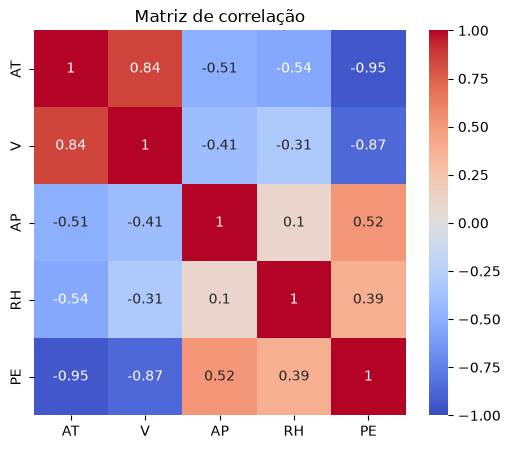

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação")
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight") 
plt.show()

In [9]:
print(df[["AT", "V", "AP", "RH"]].corr())

          AT         V        AP        RH
AT  1.000000  0.844107 -0.507549 -0.542535
V   0.844107  1.000000 -0.413502 -0.312187
AP -0.507549 -0.413502  1.000000  0.099574
RH -0.542535 -0.312187  0.099574  1.000000


In [10]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(7654, 4) (1914, 4)


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)        

In [13]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Intercepto (theta0):", model.intercept_)
for nome, coef in zip(X.columns, model.coef_):
    print(f"{nome}: {coef:.4f}")

Intercepto (theta0): 454.4310399790959
AT: -14.7639
V: -2.9496
AP: 0.3698
RH: -2.3122


In [ ]:
y_pred = model.predict(X_test_scaled) 

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²   = {r2:.4f}")
print(f"MAE  = {mae:.2f} MW")
print(f"RMSE = {rmse:.2f} MW")

R²   = 0.9301
MAE  = 3.60 MW
RMSE = 4.50 MW
